> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# **IS 4487 Lab 12: Naive Bayes, SVM, and Neural Networks**

## Outline

- Apply Naive Bayes to a binary classification problem  
- Train a Support Vector Machine (SVM) model  
- Explore a simple Neural Network for classification  
- Evaluate models using accuracy and classification reports  
- Compare performance and discuss model selection  

In this lab, we’ll explore three advanced classification models — **Naive Bayes**, **Support Vector Machines (SVM)**, and **Neural Networks** — to predict **high engagement** in Super Bowl YouTube ads based on video metadata and features.

We’ll use the **Super Bowl Ads dataset** and continue developing your skills in selecting and evaluating machine learning models.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Labs/lab_12_bayes_svm_neural.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## **Business Context: Superbowl Ads**

The dataset for this lab consists of YouTube metadata and thematic features of Super Bowl commercials.  

This dataset captures Super Bowl advertisements and their performance on YouTube, providing a valuable business context around marketing effectiveness and audience engagement. Super Bowl ads are some of the most expensive and high-profile advertisements in the world, so companies are highly interested in understanding what makes an ad successful.

Each row represents one Super Bowl ad, and the dataset includes both **video characteristics** and **performance metrics**. The video charactersistics variables in this dataset describe the content of the ads (such as whether they are funny, include celebrities, use animals, or feature patriotic themes) and their performance outcomes (counts of  views, likes, dislikes, favorites and comments).

Businesses can use this data to analyze which creative elements are associated with higher audience engagement—for example, whether humorous ads or celebrity appearances lead to more likes or shares.

For our target, we will create a metric `high_engagement` to indicate higher than median `like_count`. Using this target, analysts can  build predictive models to determine what combination of features is most likely to result in a successful ad. Insights from this type of analysis can help marketing teams design more effective campaigns, allocate advertising budgets more strategically, and maximize the return on their investment in major events like the Super Bowl.




### **Data Dictionary**

Source:  [TidyTuesday (March 2, 2021)](https://github.com/rfordatascience/tidytuesday/blob/master/data/2021/2021-03-02/youtube.csv).


Below are key variables we'll work with:

| Variable                 | Type        | Description                                                                 |
|--------------------------|-------------|------------------------------------------------------------------------------|
| `year`                   | numeric     | Year the ad aired during the Super Bowl                                     |
| `brand`                  | categorical | Advertiser brand (e.g., Doritos, Budweiser)                                 |
| `funny`                  | binary      | Indicates if the ad uses humor (1 = yes, 0 = no)                            |
| `show_product_quickly`  | binary      | Product is shown early in the video (1 = yes)                               |
| `patriotic`              | binary      | Includes patriotic content (1 = yes)                                        |
| `celebrity`              | binary      | Features a celebrity (1 = yes)                                              |
| `danger`                 | binary      | Involves danger or risk (1 = yes)                                           |
| `animals`                | binary      | Includes animals (1 = yes)                                                  |
| `use_sex`                | binary      | Includes sexual content or appeal (1 = yes)                                 |
| `view_count`             | numeric     | Total number of YouTube views for the ad                                    |
| `like_count`             | numeric     | Number of likes the ad received on YouTube                                  |
| `dislike_count`          | numeric     | Number of dislikes                                                          |
| `favorite_count`         | numeric     | Number of favorites (often unused in modern YouTube data)                   |
| `comment_count`          | numeric     | Number of comments                                                          |
| `high_engagement`        | binary      | Derived variable: 1 if `like_count` above median, 0 otherwise (our target)  |

### Why this dataset?

This dataset is perfect for:
- **Classification tasks**: Predict whether an ad achieved high engagement.
- **Marketing insights**: Identify which ad traits (e.g., humor, celebrities) drive viewer responses.
- **Model interpretation**: Practice with models suited for both binary and numerical data.

Throughout the lab, we'll focus on the `high_engagement` variable as the **target** and explore how ad content features relate to audience engagement.


## **Part 1: Load and Clean the Data**

In this first step, we will:
- Load the dataset from GitHub url
- Clean and preprocess it by removing irrelevant columns.
- Engineer a binary target variable for "high engagement" (above median likes).

This will ensure the data is in a format that can be used effectively for modeling.


In [1]:
import pandas as pd
import numpy as np

# Load dataset
url = 'https://raw.githubusercontent.com/vandanara/UofUtah_IS4487/refs/heads/main/DataSets/youtube.csv'
youtube = pd.read_csv(url)

youtube.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   year                       247 non-null    int64  
 1   brand                      247 non-null    object 
 2   superbowl_ads_dot_com_url  247 non-null    object 
 3   youtube_url                236 non-null    object 
 4   funny                      247 non-null    bool   
 5   show_product_quickly       247 non-null    bool   
 6   patriotic                  247 non-null    bool   
 7   celebrity                  247 non-null    bool   
 8   danger                     247 non-null    bool   
 9   animals                    247 non-null    bool   
 10  use_sex                    247 non-null    bool   
 11  id                         236 non-null    object 
 12  kind                       231 non-null    object 
 13  etag                       231 non-null    object 

In [2]:
# Drop irrelevant or complex API columns
youtube = youtube.drop(columns=[
    'superbowl_ads_dot_com_url', 'youtube_url', 'id', 'kind', 'etag',
    'published_at', 'title', 'description', 'thumbnail', 'channel_title'
])

# Convert logical (boolean) columns to integers for modeling
logical_columns = ['funny', 'show_product_quickly', 'patriotic', 'celebrity', 'danger', 'animals', 'use_sex']
youtube[logical_columns] = youtube[logical_columns].astype(int)

# Drop rows with missing like_count
youtube = youtube.dropna(subset=['like_count', 'view_count'])

# Create target: high_engagement
median_likes = youtube['like_count'].median()
youtube['high_engagement'] = (youtube['like_count'] > median_likes).astype(int)


# Final feature set - we will  keep a few numeric columns plus all logical columns
display(youtube[['view_count', 'like_count', 'high_engagement', 'brand'] + logical_columns].head())

print(youtube[['view_count', 'like_count', 'high_engagement', 'brand'] + logical_columns].info())

,view_count,like_count,high_engagement,brand,funny,show_product_quickly,patriotic,celebrity,danger,animals,use_sex
0,173929.0,1233.0,1,Toyota,0,0,0,0,0,0,0
1,47752.0,485.0,1,Bud Light,1,1,0,1,1,0,0
2,142310.0,129.0,0,Bud Light,1,0,0,0,1,1,0
3,198.0,2.0,0,Hynudai,0,1,0,0,0,0,0
4,13741.0,20.0,0,Bud Light,1,1,0,0,1,1,1


<class 'pandas.core.frame.DataFrame'>
Index: 225 entries, 0 to 246
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   view_count            225 non-null    float64
 1   like_count            225 non-null    float64
 2   high_engagement       225 non-null    int64  
 3   brand                 225 non-null    object 
 4   funny                 225 non-null    int64  
 5   show_product_quickly  225 non-null    int64  
 6   patriotic             225 non-null    int64  
 7   celebrity             225 non-null    int64  
 8   danger                225 non-null    int64  
 9   animals               225 non-null    int64  
 10  use_sex               225 non-null    int64  
dtypes: float64(2), int64(8), object(1)
memory usage: 21.1+ KB
None


In [3]:
youtube['brand'].value_counts()

,count
brand,
Bud Light,56
Budweiser,37
Pepsi,24
Doritos,23
Hynudai,22
Coca-Cola,20
E-Trade,12
Kia,12
Toyota,10


In [4]:
# Calculate correlations and display as a visually styled heatmap table
corr_table = youtube[['view_count', 'like_count', 'high_engagement'] + logical_columns].corr(numeric_only=True)
display(corr_table.style.background_gradient(cmap='coolwarm', axis=None).format(precision=3))

,view_count,like_count,high_engagement,funny,show_product_quickly,patriotic,celebrity,danger,animals,use_sex
view_count,1.000,0.877,0.118,0.006,0.023,0.018,-0.036,-0.021,-0.051,-0.062
like_count,0.877,1.000,0.173,-0.035,0.006,0.062,0.018,0.014,-0.035,-0.093
high_engagement,0.118,0.173,1.000,-0.070,-0.022,0.137,0.061,0.041,-0.043,-0.088
funny,0.006,-0.035,-0.070,1.000,0.087,-0.379,-0.037,0.260,0.029,0.265
show_product_quickly,0.023,0.006,-0.022,0.087,1.000,-0.065,-0.065,0.003,0.122,-0.004
patriotic,0.018,0.062,0.137,-0.379,-0.065,1.000,-0.007,-0.156,0.079,-0.144
celebrity,-0.036,0.018,0.061,-0.037,-0.065,-0.007,1.000,-0.096,-0.169,0.126
danger,-0.021,0.014,0.041,0.260,0.003,-0.156,-0.096,1.000,0.123,0.014
animals,-0.051,-0.035,-0.043,0.029,0.122,0.079,-0.169,0.123,1.000,0.026
use_sex,-0.062,-0.093,-0.088,0.265,-0.004,-0.144,0.126,0.014,0.026,1.000


## **Part 2: Naive Bayes Classifier**

Naive Bayes is a **probabilistic model** based on Bayes' Theorem. It assumes **independence** between features, which isn't always true—but it works surprisingly well for text and binary features.

There are many types of Naive Bayes classifiers,  primarily distinguished by the assumptions they make regarding the distribution of the features:

1. `GaussianNB`: when features are continous
2. `MultinomialNB`: when features are frequencies or counts (best for text classification and NLP)
3. `BernoulliNB`: when features are binary 0/1
4. `CategoricalNB`: when features are ordinal categorical and integer-encoded (1,2,3...)

#### What model to use if you have mixed feature datatypes?

Due to the naive assumption, the final posterior probability is calculated by multiplying posterior probabilities obtained from each NB model to obtain the combined prediction. For example, we would apply BernoulliNB for binary features first and then apply CategoricalNB for integer-encoded ordinal features, and then multiply the posterior probabilities from each model to get the combined prediction.


We'll use the boolean ad features (like `funny`, `celebrity`, etc.) to predict whether the video had high engagement. So we wil use `BernoulliNB`.

Ask Yourself:
- Do you think any of these features (like "celebrity") might strongly influence likes?
- How might the independence assumption affect the predictions?

Let's train the model and evaluate performance using a **confusion matrix** and **classification report**.


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Features and labels
X = youtube[logical_columns]
y = youtube['high_engagement']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit model
nb_model = BernoulliNB()
nb_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_nb = nb_model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))
print("Accuracy:", accuracy_score(y_test, y_pred_nb))

Confusion Matrix:
 [[15 12]
 [ 8 10]]

Classification Report:
               precision    recall  f1-score   support

           0       0.65      0.56      0.60        27
           1       0.45      0.56      0.50        18

    accuracy                           0.56        45
   macro avg       0.55      0.56      0.55        45
weighted avg       0.57      0.56      0.56        45

Accuracy: 0.5555555555555556


### **🔧 Try It Yourself - Part 2**

2.1. **Change the test size** to `0.3`. How does this affect accuracy?  
   > Update `train_test_split(test_size=0.3)` and rerun the model.


In [ ]:
# 🔧 2.1 Add code here

2.2. **Increase the feature set to include brand dummies**.

There are 10 brands in the `brand` column.
First, convert the brand column into one-hot encodings, which produces binary dummy columns. Since all features are still binary, you can use `BernoulliNB`.

Rerun the model and check performance.  





In [ ]:
# 🔧 2.2 Add code here

### Please answer the following question.

2.3. Which model /set of features performed best? Why might that be?

2.4. Is accuracy a good metric to use in this case? Do we need to be concerned about it? Think about the target - it balanced or not?



### ✍️ Your Response: 🔧

2.3.


2.4

## **Part 3: Support Vector Machine (SVM)**

### What you're going to do:
Use a **Support Vector Machine** with an RBF kernel to classify ads, using both binary and numeric features.

The SVM section begins by selecting the input features and target, then splitting the data into training and test sets to ensure fair evaluation. The features are ***scaled using a StandardScaler*** fit only on the training data so that all variables are on a comparable scale, which is important for SVM performance.

A support vector machine model is then trained on the scaled training data, optionally using cross-validation to tune hyperparameters like the kernel and regularization strength.

Finally, the trained model is used to make predictions on the untouched test set, and its performance is evaluated using metrics such as accuracy and a confusion matrix.

### Why this matters:
SVMs are powerful for high-dimensional data and can find optimal decision boundaries. They are also common in fraud detection and image recognition.

## Tuning an SVM

### Regularization hyperparameter (C):

- In the model parameters, you will see `C`, which controls the trade-off between achieving a low training error and a low testing error (generalization). ***C is the inverse of the regularization strength*** (in SVM, how wide or soft the margin is)

- A large `C` value (e.g., C = 1000) = low regularization, means the model will try to classify all training examples correctly, even if that leads to overfitting. Uses a narrow, less soft margin.

- A small `C` value (e.g., C = 0.01) = high regularizaton, means the model will allow some misclassifications in the training data, encouraging a wider/softer margin and potentially better generalization.

- C = 1 is a good balance


### Kernel:

- determines the type of boundary to draw, linear or non-linear.

### Gamma:

- for non-linear kernels determines the influence of each data point

### What to notice:
- How does scaling the data affect performance?
- What happens when you change the kernel or regularization?

In [7]:
# Let us create and add brand dummies to our feature set
brand_dummies = pd.get_dummies(youtube['brand'], prefix='brand', drop_first=True).astype(int)
youtube = pd.concat([youtube, brand_dummies], axis=1)

In [9]:
from sklearn.svm import SVC

# Concatenate the list of logical columns with the list of dummy column names
X = youtube[logical_columns + list(brand_dummies.columns)]
y = youtube['high_engagement']

# Split
X_train_svm, X_test_svm, y_train_svm, y_test_svm = train_test_split(X, y, test_size=0.2, random_state=42)

# Train SVM
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_model.fit(X_train_svm, y_train_svm)

# Predict
y_pred_svm = svm_model.predict(X_test_svm)

# Evaluate
print("Confusion Matrix:\n", confusion_matrix(y_test_svm, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test_svm, y_pred_svm))
print("Accuracy:", accuracy_score(y_test_svm, y_pred_svm))

Confusion Matrix:
 [[16 11]
 [ 7 11]]

Classification Report:
               precision    recall  f1-score   support

           0       0.70      0.59      0.64        27
           1       0.50      0.61      0.55        18

    accuracy                           0.60        45
   macro avg       0.60      0.60      0.59        45
weighted avg       0.62      0.60      0.60        45

Accuracy: 0.6


### **🔧 Try It Yourself — Part 3**

3.1. Write code to **vary the hyperparameters to tune the model**.

Change the kernel to `'linear'` or `'poly'`.  
Try a least 3 different `C` values** like `0.1`, `2`, and `10`, `100` ....

Observe how performance changes.




### Please answer the following questions.

3.2. What’s the tradeoff between higher vs. lower values of `C`?


3.3. Which value of `C` and `kernel` gave you the best Accuracy?  

3.4. Adding `view_count` as a predictor increases accuracy to 75%; is it appropriate to use it as a predictor to predict `high_engagement` based on `like_count`? why or why not?



### ✍️ Your Response: 🔧

3.2.

3.3.

3.4.

## **Part 4: Neural Networks**

### What we're going to do:
Build a basic **feedforward neural network** to classify ad engagement.

First, we define the input features (X) and the target variable (y). Then, we split the dataset into three parts:
- a training set used to learn the model,
- a validation set used to monitor performance during training, and
- a test set reserved for final evaluation.

After splitting, the features can be scaled using a StandardScaler (if needed; dont need to scale binary features), which is fit only on the training data and then applied to the validation and test sets to keep everything consistent without introducing leakage.

Next, the neural network is built using a series of ***dense layers***, ending with a ***sigmoid*** output for binary classification. The model is then compiled, specifying how it will learn (***`adam` optimizer***), how errors are measured (***`cross-entropy` as loss function***), and what metrics to track (***accuracy***).

Then we fit the model and specify the ***batch size*** and ***epochs*** to use.

During training, the model learns from the training data while periodically evaluating itself on the validation set to track progress and detect overfitting. Once training is complete, the model makes predictions on the untouched test set, and its performance is evaluated using metrics like accuracy, a confusion matrix, and a classification report. This entire flow ensures that the model is trained properly and evaluated fairly on data it has never seen before.

### Why this matters:
Neural networks are the foundation of modern AI. Even a simple one can outperform traditional models when tuned correctly. However they are black box models.

### What to notice:
- This may take several minutes to run!  Be patient.
- How does training accuracy compare to validation accuracy?
- Do more layers or epochs help — or hurt?


In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Prepare features and target as float
X_nn = youtube[logical_columns + list(brand_dummies.columns)].astype(float)
y_nn = youtube['high_engagement'].astype(float)

# 1. Hold out the final test set (15% of the total dataset)
X_temp, X_test_nn, y_temp, y_test_nn = train_test_split(
    X_nn, y_nn, test_size=0.15, random_state=42, stratify=y_nn
)

# 2. Split the remaining 85% of the dataset into Train and Validation (approx. 70% and 15% of the total)
# test_size = 0.176 approx equates to 15% of the total (0.15 / 0.85 = 0.176)
X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp
)

# Define Model Architecture
model = Sequential([
    Dense(16, activation='relu'),   # Input Layer
    Dense(8, activation='relu'),    # Hidden Layer 1
    Dense(4, activation='relu'),    # Hidden Layer 2
    Dense(1, activation='sigmoid')  # Output Layer
])

# Compile
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train using the validation data to monitor progress
history = model.fit(X_train_nn, y_train_nn, validation_data=(X_val_nn, y_val_nn),
                    epochs=20, batch_size=16, verbose=1)

# Predict and evaluate on the completely unseen final test set
y_pred_nn = (model.predict(X_test_nn) > 0.5).astype(int)
print("\n--- Final Evaluation on Untouched Test Set ---")
print("Confusion Matrix:\n", confusion_matrix(y_test_nn, y_pred_nn))
print("\nClassification Report:\n", classification_report(y_test_nn, y_pred_nn))
print("Accuracy:", accuracy_score(y_test_nn, y_pred_nn))

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5287 - loss: 0.6950 - val_accuracy: 0.4412 - val_loss: 0.6948
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5287 - loss: 0.6933 - val_accuracy: 0.4118 - val_loss: 0.6941
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5478 - loss: 0.6920 - val_accuracy: 0.4706 - val_loss: 0.6942
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5478 - loss: 0.6906 - val_accuracy: 0.5294 - val_loss: 0.6933
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5478 - loss: 0.6894 - val_accuracy: 0.5294 - val_loss: 0.6924
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5287 - loss: 0.6883 - val_accuracy: 0.5000 - val_loss: 0.6921
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5796 - loss: 0.6872 - val_accuracy: 0.5294 - val_loss: 0.6919
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5287 - loss: 0.6859 - val_accuracy: 0.5588 - v

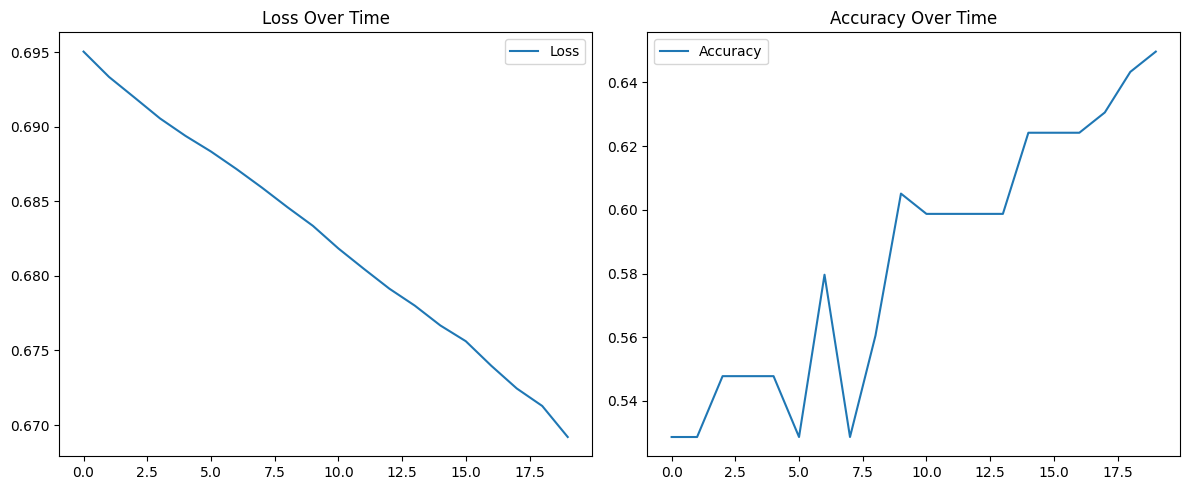

In [13]:
# Plot learning curves
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss')
plt.title('Loss Over Time')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy')
plt.title('Accuracy Over Time')
plt.legend()
plt.tight_layout()
plt.show()

### **🔧 Try It Yourself — Part 4**

4.1. Try out **5 different combinations of different batch sizes and layers**. Notice if these changes affect ms/step for each Epoch. Also notice how the accuracy changes as you alter layers and batch size.

- Add or remove layers from the model.

- Increase or decrease batch size to numbers such as 8 or 32.


4.2. **Add Dropout** to your model



### Please answer the following questions:

4.3. What was the optimal number of layers and batch size that you were able to find?  (Remember, you should try about 5 different combinations)


4.4. Does adding `Dropout` help reduce overfitting? `Dropout` is a hyperparameter that allows us to drop some neuron-to-neuron connections to potentially reduce overfitting.

Use the "loss over time" plot to support your answer.


### ✍️ Your Response: 🔧

4.3.


4.4.

## 🔧 **Part 5: Reflection (100 words or less per question)**

5.1. Which model performed best on your dataset? Is this the result you expected?

5.2. Did any of the models appear to be overfit or underfit? How could you tell?

5.3. Which model would you recommend to a marketing team for this type of data and why?

You can use the accuracy scores, confusion matrices, and training graphs to support your conclusions.


### ✍️ Your Response: 🔧
5.1.

5.2.

5.3.

## Export Your Notebook to Submit in Canvas
- Use the instructions from Lab 1

In [ ]:
!jupyter nbconvert --to html "lab_12_LastnameFirstname.ipynb"